# SPHEREx Flipbook: tutorial

This notebook uses the `spherex` library (the part of the SPHEREx Flipbook that does the work)
to look at **WISE 0855**, the coldest known brown dwarf. You'll see its visits, the video
frames, a difference picture, a catalogue overlay, a light curve and a spectrum.

Every call goes through `spherex.api`, the same interface the web app uses (`docs/API.md`).

**First run:** a target's images come from NASA's IRSA archive the first time (about 1-3 min
for a target), and from the local cache afterwards. The outputs saved in this notebook were
made from an existing cache, with no downloads.

## Install

In a terminal, or uncomment the line below:

```
pipx install git+https://github.com/UTMOS12345/spherex_project.git   # the app, and the library
# or, into the environment running this notebook:
pip install git+https://github.com/UTMOS12345/spherex_project.git
```

In [1]:
# %pip install git+https://github.com/UTMOS12345/spherex_project.git

## Setup

`set_style()` gives every figure the same look; `display(fig)` shows a figure here. `api.set_demo_mode(True)` makes the library
use only data already on disk (no downloads). Leave it commented out to let the library
download what it needs.

In [2]:
import matplotlib.pyplot as plt
from IPython.display import Image, display
from spherex import api, set_style
%matplotlib inline

set_style(dark=False)
# api.set_demo_mode(True)        # only data already downloaded

TARGET = "WISE 0855"
print(api.resolve(TARGET))
settings = api.defaults(TARGET)   # detector and light-curve wavelength chosen for this target
settings

{'name': 'WISE 0855', 'ra': 133.795129, 'dec': -7.245147, 'ra_hms': '08h55m10.8s', 'dec_dms': '-07d14m42.5s', 'has_motion': True, 'pm_ra': -8118.0, 'pm_dec': 680.0, 'known': True}


{'detector': 'D6', 'band': 4.5, 'tol': 0.02}

`resolve` turns a name or coordinates into a position, with the target's proper motion
when it is known. WISE 0855 moves about 8″ per year, and its catalogue position is from about
2010.4.

## 1. Visits

SPHEREx scans each part of the sky about every six months. A **visit** is one of those passes.
Each visit holds many **frames** (exposures) on the six detectors D1-D6, each detector covering
a different wavelength range.

In [3]:
visits = api.visits(TARGET)
visits

visit,first_date,last_date,n_frames,D1,D2,D3,D4,D5,D6,releases
int64,str10,str10,int64,int64,int64,int64,int64,int64,int64,str3
0,2025-05-05,2025-05-06,30,4,8,3,4,8,3,dr1
1,2025-10-31,2025-12-13,128,18,25,21,18,25,21,dr1
2,2026-04-21,2026-05-14,100,14,15,21,14,15,21,dr1


## 2. Video frames

`api.epochs` lists the pictures that the video and the picture functions build for these
settings: one per visit, stacked from that visit's frames. A picture with fewer than 4 frames
under its centre is marked `few_frames` (unreliable).

`api.flipbook` makes the animated GIF. The green circle is where the proper motion puts the
target on each date.

In [4]:
det = settings["detector"]
epochs = api.epochs(TARGET, detector=det, fov=4.0)
print(epochs.meta)
epochs["index", "date", "n_frames", "n_min", "few_frames", "releases"]

{'n_pictures': 3, 'n_frames_total': 45, 'n_few_frames': 1}


index,date,n_frames,n_min,few_frames,releases
int64,str10,int64,int64,bool,str3
0,2025-05-05,3,3,True,DR1
1,2025-11-16,21,21,False,DR1
2,2026-04-27,21,21,False,DR1


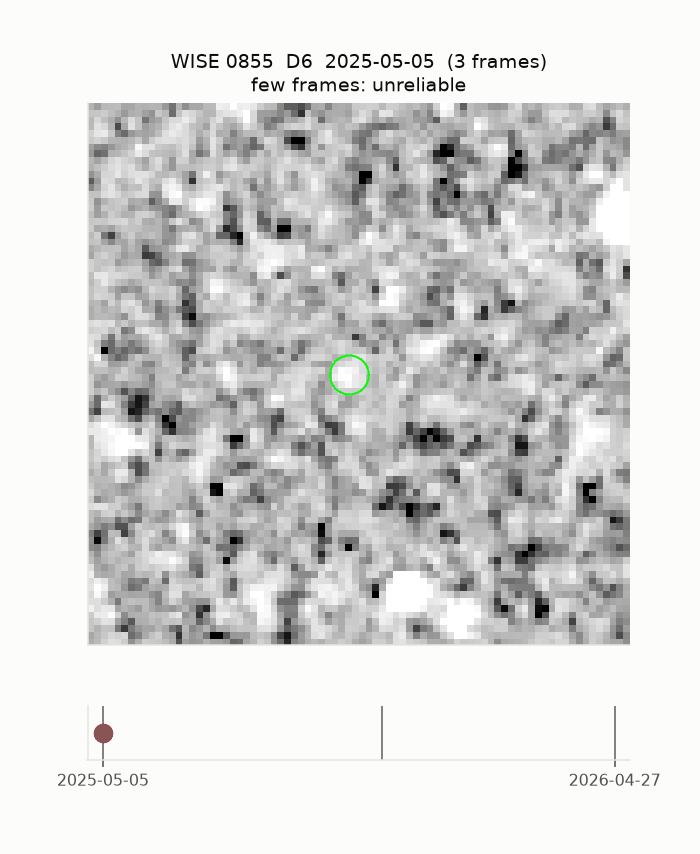

In [5]:
gif = api.flipbook(TARGET, detector=det, fov=4.0, fps=2)
display(Image(data=gif, format="gif"))

## 3. Difference picture

The later visit minus the earlier one (`a=-1` is the last picture, `b=0` the first), on the
same sky grid. Red means brighter later, blue means brighter earlier. A moving object leaves a
red/blue pair; a constant star cancels.

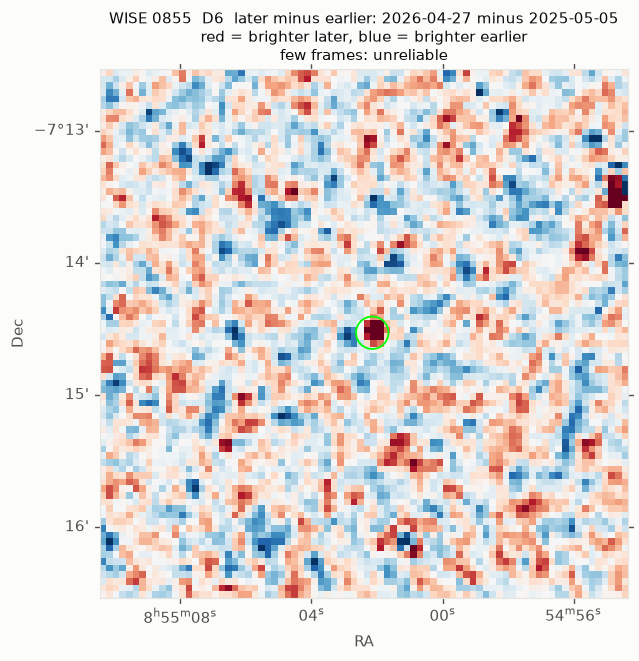

In [6]:
fig = api.picture(TARGET, kind="pair", detector=det, fov=4.0, a=-1, b=0)
display(fig); plt.close(fig)

## 4. Overlay

Gaia DR3 and CatWISE2020 sources, moved to the date of the picture, with arrows for large
proper motions. The notes say what was found near the target.

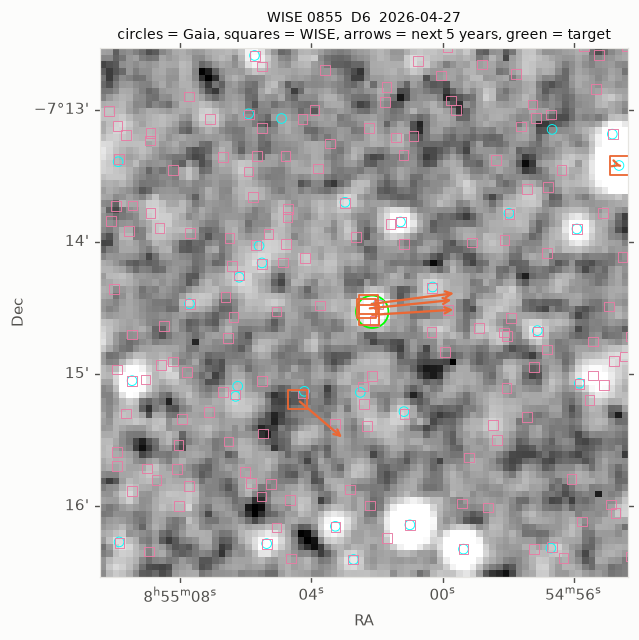

{'nearest_gaia_arcsec': 4.508652001281736,
 'in_gaia': False,
 'wise_halo_stars': 0,
 'nearest_wise_arcsec': 2.071568203915886,
 'in_wise': True,
 'verdict': "Catalogue check: a CatWISE2020 source lies within 3″ of the target's predicted position, none in Gaia (a known object that is faint or cold in visible light).",
 'n_min': 21,
 'clipped_fraction': 0.011212797619047619,
 'few_frames': False}

In [7]:
fig, notes = api.overlay_figure(TARGET, detector=det, fov=4.0, visit=-1)
display(fig); plt.close(fig)
{k: v for k, v in notes.items() if not isinstance(v, (list, dict))}

## 5. Light curve

Brightness at one wavelength over time. Each frame sees the target at its own wavelength, so
only frames within ±`tol` µm of the chosen wavelength are used, and every point is labelled with
its wavelength. `table.meta["warning"]` explains the caveats in words. For WISE 0855, a Gaia
star 4-6″ away (the distance changes as WISE 0855 moves) is inside the measuring circle.

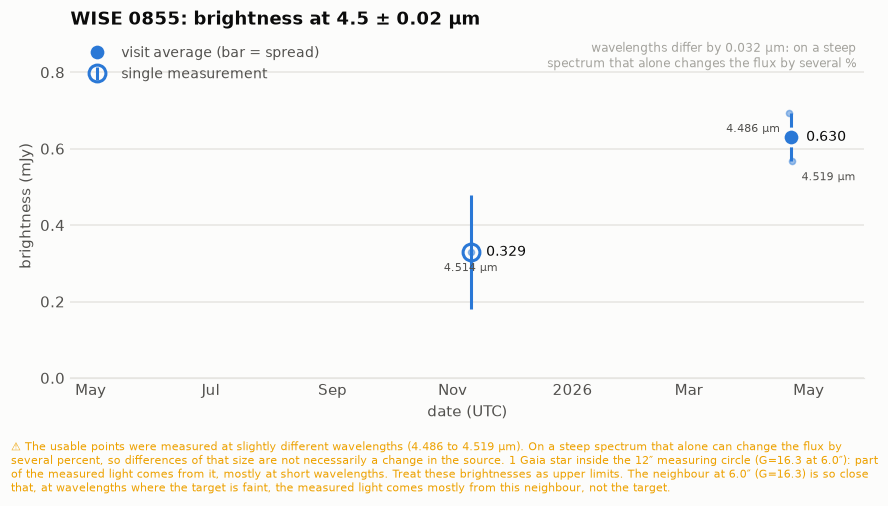

The usable points were measured at slightly different wavelengths (4.486 to 4.519 µm). On a steep spectrum that alone can change the flux by several percent, so differences of that size are not necessarily a change in the source. 1 Gaia star inside the 12″ measuring circle (G=16.3 at 6.0″): part of the measured light comes from it, mostly at short wavelengths. Treat these brightnesses as upper limits. The neighbour at 6.0″ (G=16.3) is so close that, at wavelengths where the target is faint, the measured light comes mostly from this neighbour, not the target.


date,wavelength_um,flux_mjy,err_mjy,release,ok
,um,mJy,mJy,,
str23,float64,float64,float64,str3,bool
2025-11-10 07:13:01.073,4.481,0.94,0.15,DR1,False
2025-11-10 07:15:10.004,4.514,0.33,0.15,DR1,True
2026-04-21 04:50:16.850,4.486,0.69,0.13,DR1,True
2026-04-22 18:11:28.589,4.519,0.57,0.14,DR1,True


In [8]:
fig, lc = api.light_curve_figure(TARGET, band=settings["band"], tol=settings["tol"])
display(fig); plt.close(fig)
print(lc.meta.get("warning"))
lc["date", "wavelength_um", "flux_mjy", "err_mjy", "release", "ok"]

## 6. Spectrum

The spectrum of the latest visit, measured from the images and binned into the 102 SPHEREx
channels. WISE 0855 is only bright at 4-5 µm. At shorter wavelengths the light mostly comes
from the neighbouring star, and the figure says so.

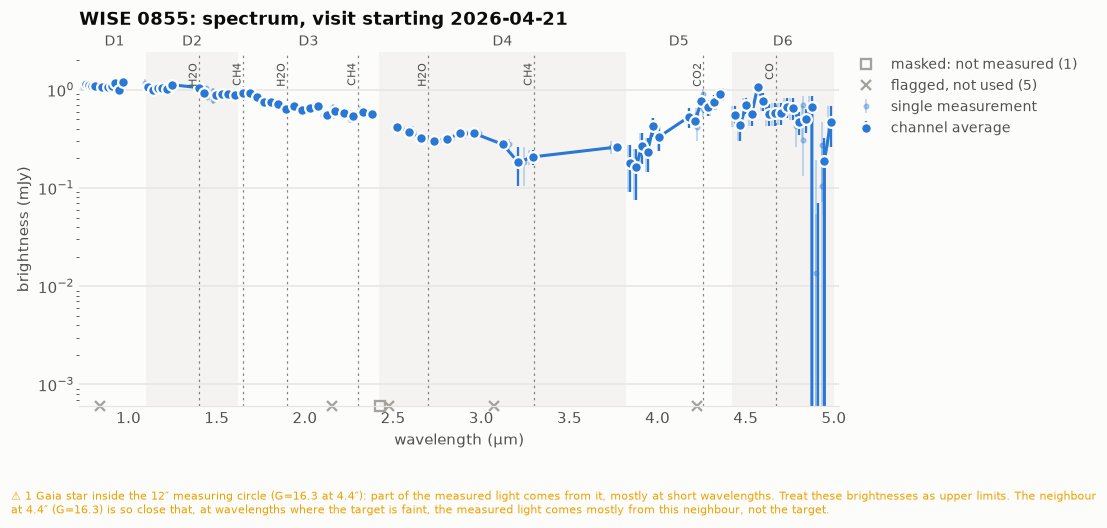

1 Gaia star inside the 12″ measuring circle (G=16.3 at 4.4″): part of the measured light comes from it, mostly at short wavelengths. Treat these brightnesses as upper limits. The neighbour at 4.4″ (G=16.3) is so close that, at wavelengths where the target is faint, the measured light comes mostly from this neighbour, not the target.


In [9]:
fig, spec = api.spectrum_figure(TARGET, visit=-1)
display(fig); plt.close(fig)
print(spec.meta.get("warning"))

## Next

- Try another target: a name (`"Barnard's Star"`), degrees (`"133.795 -7.245"`) or
  sexagesimal coordinates (`"08h55m10.8s -07d14m42.5s"`).
- `api.flipbook(..., mode="difference")` shows each visit minus the first.
- `api.spectrum_figure(..., all_visits=True)` gives one spectrum per visit.
- The web app (`paramost`) shows all of this interactively. The full reference is
  [docs/API.md](../docs/API.md).